In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
fake_df = pd.read_csv('Fake.csv')
true_df = pd.read_csv('True.csv')

print("Fake News Dataset:", fake_df.shape)
print("Real News Dataset:", true_df.shape)

print("\nFake News:")
display(fake_df.head())

print("\nReal News:")
display(true_df.head())

Fake News Dataset: (23481, 4)
Real News Dataset: (21417, 4)

Fake News:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



Real News:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [3]:
fake_df['label'] = 0
true_df['label'] = 1

df = pd.concat([fake_df, true_df], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Combined Dataset Shape:", df.shape)

display(df.head())

Combined Dataset Shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB

Dataset Shape:
(44898, 5)

Column Names:
['title', 'text', 'subject', 'date', 'label']


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [6]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 209


In [7]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (44689, 5)
Remaining Duplicates: 0


News Distribution:
label
0    23478
1    21211
Name: count, dtype: int64


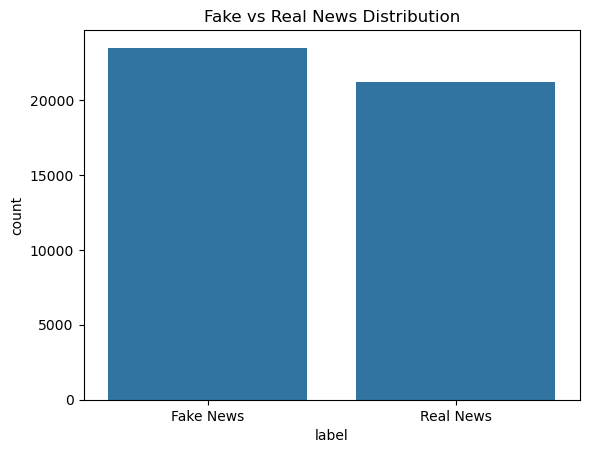

In [8]:
print("News Distribution:")
print(df['label'].value_counts())

sns.countplot(x='label', data=df)
plt.title("Fake vs Real News Distribution")
plt.xticks([0, 1], ['Fake News', 'Real News'])
plt.show()

In [9]:
df.to_csv('ISOT_Cleaned_Dataset.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [10]:
import pandas as pd
import os

df = pd.read_csv("ISOT_Cleaned_Dataset.csv")

rows_per_file = 50000

for i in range(0, len(df), rows_per_file):
    part = df.iloc[i:i+rows_per_file]
    part.to_csv(f"ISOT_Dataset_Part_{i//rows_per_file + 1}.csv",
                index=False)

print("Dataset splitting completed!")

Dataset splitting completed!


In [11]:
import os

print(os.path.getsize("ISOT_Dataset_Part_1.csv") / (1024 * 1024), "MB")

110.46636295318604 MB


In [12]:
rows_per_file = 5000

for i in range(0, len(df), rows_per_file):
    part = df.iloc[i:i+rows_per_file]
    part.to_csv(
        f"ISOT_Small_Part_{i//rows_per_file + 1}.csv",
        index=False
    )

print("Small parts created successfully!")

Small parts created successfully!


In [13]:
import glob
import os

for file in glob.glob("ISOT_Small_Part_*.csv"):
    size = os.path.getsize(file) / (1024 * 1024)
    print(file, ":", round(size, 2), "MB")

ISOT_Small_Part_1.csv : 12.44 MB
ISOT_Small_Part_2.csv : 12.23 MB
ISOT_Small_Part_3.csv : 12.46 MB
ISOT_Small_Part_4.csv : 12.3 MB
ISOT_Small_Part_5.csv : 12.27 MB
ISOT_Small_Part_6.csv : 12.47 MB
ISOT_Small_Part_7.csv : 12.39 MB
ISOT_Small_Part_8.csv : 12.29 MB
ISOT_Small_Part_9.csv : 11.63 MB


In [14]:
print("hello")

hello


In [15]:
df = pd.read_csv('ISOT_Cleaned_Dataset.csv')

print("Dataset loaded successfully!")
print(df.shape)
df.head()

Dataset loaded successfully!
(44689, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [16]:
print(df.columns)

Index(['title', 'text', 'subject', 'date', 'label'], dtype='object')


In [17]:
df['text'].head()

0    21st Century Wire says Ben Stein, reputable pr...
1    WASHINGTON (Reuters) - U.S. President Donald T...
2    (Reuters) - Puerto Rico Governor Ricardo Rosse...
3    On Monday, Donald Trump once again embarrassed...
4    GLASGOW, Scotland (Reuters) - Most U.S. presid...
Name: text, dtype: object

In [18]:
df['text'].isnull().sum()

np.int64(0)

In [19]:
df['text'] = df['text'].str.lower()

df['text'].head()

0    21st century wire says ben stein, reputable pr...
1    washington (reuters) - u.s. president donald t...
2    (reuters) - puerto rico governor ricardo rosse...
3    on monday, donald trump once again embarrassed...
4    glasgow, scotland (reuters) - most u.s. presid...
Name: text, dtype: object

In [20]:
df['text'] = df['text'].str.replace(r'http\S+|www\S+', '', regex=True)

df['text'].head()

0    21st century wire says ben stein, reputable pr...
1    washington (reuters) - u.s. president donald t...
2    (reuters) - puerto rico governor ricardo rosse...
3    on monday, donald trump once again embarrassed...
4    glasgow, scotland (reuters) - most u.s. presid...
Name: text, dtype: object

In [21]:
df['text'] = df['text'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

df['text'].head()

0    st century wire says ben stein reputable profe...
1    washington reuters  us president donald trump ...
2    reuters  puerto rico governor ricardo rossello...
3    on monday donald trump once again embarrassed ...
4    glasgow scotland reuters  most us presidential...
Name: text, dtype: object

In [22]:
df['text'] = df['text'].str.replace(r'\s+', ' ', regex=True).str.strip()

df['text'].head()

0    st century wire says ben stein reputable profe...
1    washington reuters us president donald trump r...
2    reuters puerto rico governor ricardo rossello ...
3    on monday donald trump once again embarrassed ...
4    glasgow scotland reuters most us presidential ...
Name: text, dtype: object

In [23]:
X = df['text']
y = df['label']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (44689,)
Output shape: (44689,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (35751,)
Testing data: (8938,)


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

print("Machine Learning algorithms imported successfully!")

Machine Learning algorithms imported successfully!


In [27]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [28]:
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [29]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [31]:
X = df['text']
y = df['label']

print(X.shape)
print(y.shape)

(44689,)
(44689,)


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('ISOT_Cleaned_Dataset.csv')

print("Dataset loaded successfully!")
print(df.shape)

In [ ]:
X = df['text']
y = df['label']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [36]:
print('df:', 'df' in globals())
print('X_train:', 'X_train' in globals())
print('tfidf:', 'tfidf' in globals())
print('X_train_tfidf:', 'X_train_tfidf' in globals())

df: True
X_train: True
tfidf: True
X_train_tfidf: True


In [37]:
print(tfidf)

TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words='english')


In [38]:
X_train_tfidf = tfidf.transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [39]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


In [40]:
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [41]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression predictions completed!")

Logistic Regression predictions completed!


In [42]:
nb_model = MultinomialNB()

print("Naive Bayes model created successfully!")

Naive Bayes model created successfully!


In [43]:
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [44]:
svm_model = LinearSVC(random_state=42)

print("SVM model created successfully!")

SVM model created successfully!


In [45]:
svm_model.fit(X_train_tfidf, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [46]:
y_pred_nb = nb_model.predict(X_test_tfidf)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("All three models predictions completed successfully!")

All three models predictions completed successfully!


In [47]:
print("Logistic Regression:", len(y_pred_lr))
print("Naive Bayes:", len(y_pred_nb))
print("SVM:", len(y_pred_svm))

Logistic Regression: 8938
Naive Bayes: 8938
SVM: 8938


In [48]:
import joblib

joblib.dump(lr_model, 'logistic_regression_model.pkl')
joblib.dump(nb_model, 'naive_bayes_model.pkl')
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("All models and TF-IDF vectorizer saved successfully!")

All models and TF-IDF vectorizer saved successfully!


In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [50]:
print("Logistic Regression Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Logistic Regression Evaluation
Accuracy: 0.987692996196017
Precision: 0.9827102803738318
Recall: 0.9915134370579916
F1 Score: 0.9870922318704529


In [51]:
print('df:', 'df' in globals())
print('X_train:', 'X_train' in globals())
print('X_test:', 'X_test' in globals())
print('y_train:', 'y_train' in globals())
print('y_test:', 'y_test' in globals())
print('tfidf:', 'tfidf' in globals())
print('lr_model:', 'lr_model' in globals())
print('y_pred_lr:', 'y_pred_lr' in globals())

df: True
X_train: True
X_test: True
y_train: True
y_test: True
tfidf: True
lr_model: True
y_pred_lr: True


In [52]:
print("Logistic Regression Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Logistic Regression Evaluation
Accuracy: 0.987692996196017
Precision: 0.9827102803738318
Recall: 0.9915134370579916
F1 Score: 0.9870922318704529


In [53]:
print("Naive Bayes Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

Naive Bayes Evaluation
Accuracy: 0.9531215036921011
Precision: 0.9528547737502961
Recall: 0.9481376709099482
F1 Score: 0.9504903698452085


In [54]:
print("SVM Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

SVM Evaluation
Accuracy: 0.9945177892145894
Precision: 0.9924829692271553
Recall: 0.995992456388496
F1 Score: 0.9942346158371573


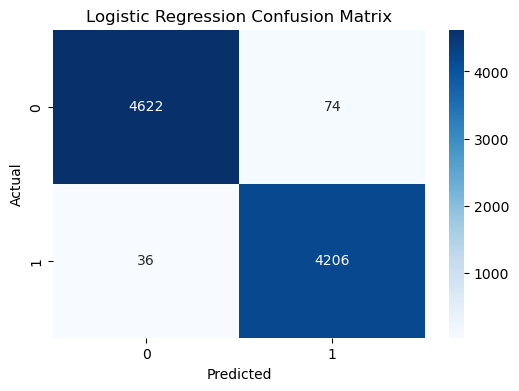

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

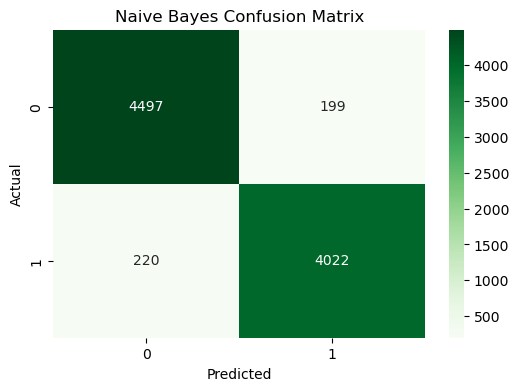

In [56]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens')
plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

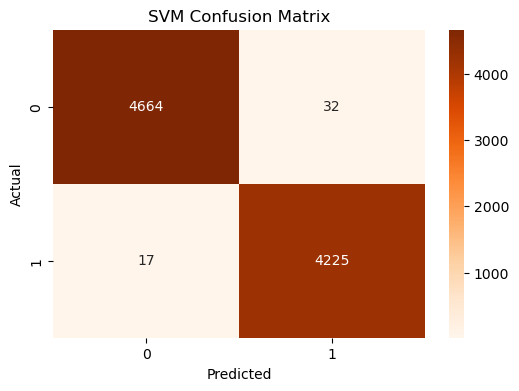

In [57]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges')
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [58]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Naive Bayes', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_svm)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_svm)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_svm)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.987693,0.982710,0.991513,0.987092
1,Naive Bayes,0.953122,0.952855,0.948138,0.950490
2,SVM,0.994518,0.992483,0.995992,0.994235


In [59]:
results.to_csv('Model_Evaluation_Results.csv', index=False)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [60]:
import os

print(os.getcwd())
print(os.path.exists('Model_Evaluation_Results.csv'))

C:\Users\HP\datascience\Fake News Detection
True


In [61]:
import importlib.util

print(importlib.util.find_spec("streamlit"))

ModuleSpec(name='streamlit', loader=<_frozen_importlib_external.SourceFileLoader object at 0x000001DB4A417AD0>, origin='C:\\Users\\HP\\anaconda3\\Lib\\site-packages\\streamlit\\__init__.py', submodule_search_locations=['C:\\Users\\HP\\anaconda3\\Lib\\site-packages\\streamlit'])


In [62]:
import pandas as pd

true_news = pd.read_csv('True.csv')
print(true_news['text'].iloc[0])

WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they return from the holidays on Wednesday, lawmakers will begin trying to pass a federal budget in a fight likely to be linked to other issues, such as immigration policy, even as the November congressional election campaigns approach in which Republicans will seek to keep control of Congress. President Donald Trump and his Republicans want a big budget increase in military spending, while Democrats also want proportional increases for non-defense “discretionary” spending on programs that support educati

In [63]:
fake_news = pd.read_csv('Fake.csv')
print(fake_news['text'].iloc[10])

A centerpiece of Donald Trump s campaign, and now his presidency, has been his white supremacist ways. That is why so many of the public feuds he gets into involve people of color. One of his favorite targets, is, of course, the players in the National Football League who dare to exercise their First Amendment rights by kneeling during the national anthem in protest of racist police brutality. Well, there is one person who has figured out that racism is bad for business, even if it did get the orange overlord elected: The founder of the pizza chain Papa John s.This is a man who has never been on the right side of history on any number of issues, and plus his pizza sucks. But, when he decided to complain about the players protesting, his sales really dropped. Turns out racism doesn t pay, and we all know that corporations are all about the bottom line. Therefore, Papa John Schnatter will no longer be CEO of the hack pizza chain.BREAKING: Papa John's founder John Schnatter to step down a

In [64]:
import pandas as pd

true_news = pd.read_csv("True.csv")
print(true_news["text"].iloc[0])

WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they return from the holidays on Wednesday, lawmakers will begin trying to pass a federal budget in a fight likely to be linked to other issues, such as immigration policy, even as the November congressional election campaigns approach in which Republicans will seek to keep control of Congress. President Donald Trump and his Republicans want a big budget increase in military spending, while Democrats also want proportional increases for non-defense “discretionary” spending on programs that support educati

In [65]:
fake_news = pd.read_csv("Fake.csv")
print(fake_news["text"].iloc[10])

A centerpiece of Donald Trump s campaign, and now his presidency, has been his white supremacist ways. That is why so many of the public feuds he gets into involve people of color. One of his favorite targets, is, of course, the players in the National Football League who dare to exercise their First Amendment rights by kneeling during the national anthem in protest of racist police brutality. Well, there is one person who has figured out that racism is bad for business, even if it did get the orange overlord elected: The founder of the pizza chain Papa John s.This is a man who has never been on the right side of history on any number of issues, and plus his pizza sucks. But, when he decided to complain about the players protesting, his sales really dropped. Turns out racism doesn t pay, and we all know that corporations are all about the bottom line. Therefore, Papa John Schnatter will no longer be CEO of the hack pizza chain.BREAKING: Papa John's founder John Schnatter to step down a